# Voice-Based ERP Assistant — Synthetic Dataset Generator (v2, expanded)

**Why this version exists:** the first version of this dataset (507 rows) was reviewed by the
project mentor, who flagged it as **too small**. This version scales up the dataset by:

1. Expanding every word list (more names, subjects, dates, marks values, leave reasons)
2. Adding more sentence templates per intent (more phrasing variety, not just more repeats)
3. Increasing the number of generated variants per template
4. Adding a light paraphrase layer (casual/contracted phrasings) for extra natural variety

This produces a dataset in the thousands of rows rather than hundreds, with much more
combinatorial diversity, while still being fully labeled by construction (no manual annotation
needed, since we generate the sentence and therefore already know its intent and entities).


In [1]:
import random
import pandas as pd

random.seed(42)  # reproducibility


## 1. Word lists (expanded)

Significantly larger pools of sample values than v1 — this is the main lever for scale, since
every extra name/subject/date multiplies the number of unique sentences each template can produce.


In [2]:
students = [
    "Rahul Sharma", "Ananya Iyer", "Kota Sandeep", "Riksheta Brahma", "Sai Siddarth",
    "Eeshritha", "Priya Verma", "Arjun Mehta", "Fatima Khan", "Vikram Singh",
    "Sneha Reddy", "Karthik Nair", "Divya Menon", "Rohan Gupta", "Ishita Das",
    "Aditya Rao", "Meera Pillai", "Yash Malhotra", "Kavya Krishnan", "Nikhil Joshi",
    "Pooja Desai", "Aryan Kapoor", "Tanvi Bhatt", "Siddharth Rana", "Anjali Sinha",
    "Harsh Vardhan", "Neha Choudhary", "Varun Kulkarni", "Riya Agarwal", "Manav Trivedi",
    "Simran Kaur", "Aakash Bose", "Lavanya Subramaniam", "Dev Patel", "Shreya Bansal",
    "Om Prakash", "Nandini Rao", "Kabir Mehra", "Ira Shetty", "Aditi Chauhan",
    "Rohit Kumar", "Sanya Malik", "Vivaan Chandra", "Diya Saxena", "Krishna Murthy",
    "Aarav Bhatia", "Sara Thomas", "Yuvraj Singh", "Anushka Gowda", "Dhruv Mishra",
]

subjects = [
    "Machine Learning", "Data Structures", "Operating Systems", "DBMS",
    "Computer Networks", "Software Engineering", "Artificial Intelligence",
    "Web Technologies", "Mathematics", "Digital Electronics",
    "Theory of Computation", "Compiler Design", "Cloud Computing",
    "Cybersecurity", "Data Mining", "Computer Graphics", "Discrete Mathematics",
    "Python Programming", "Java Programming", "Deep Learning",
]

marks_values = list(range(30, 101, 1))  # 30 to 100 inclusive

dates = [
    "today", "yesterday", "this Monday", "last Friday", "on 5th August",
    "on 12th September", "this week", "tomorrow", "next Monday", "this month",
    "on 3rd October", "last week", "this semester", "on 20th November",
    "next week", "on 15th July", "this Tuesday", "day after tomorrow",
]

leave_reasons = [
    "medical leave", "personal reasons", "a family function", "a conference",
    "official work", "a workshop", "a health checkup", "a family emergency",
    "a training program", "personal work",
]

politeness = ["", "please ", "kindly ", "could you "]


## 2. Intent templates (expanded)

Each intent now has roughly double the templates of v1, including more casual/contracted
phrasings ("mark's" -> "mark", short imperative forms, question forms) so the classifier sees
more of the natural variety a real faculty member might actually use.


In [3]:
intent_templates = {
    "mark_attendance": [
        "{pol}mark attendance for {student} in {subject}",
        "{pol}mark {student} present in {subject} class",
        "{pol}record attendance of {student} for {subject}",
        "{pol}take attendance for {student} today in {subject}",
        "{student} is present in {subject}, mark it",
        "{pol}mark {student} absent in {subject}",
        "{pol}update attendance status of {student} in {subject}",
        "attendance for {student} in {subject}, mark present",
        "{pol}log {student} as present for {subject}",
        "{pol}set {student}'s attendance in {subject} to present",
    ],
    "update_marks": [
        "{pol}update marks of {student} to {marks} in {subject}",
        "{pol}set {student}'s {subject} marks to {marks}",
        "{pol}change the score of {student} in {subject} to {marks}",
        "{pol}give {student} {marks} marks in {subject}",
        "{pol}update {subject} grade for {student} to {marks}",
        "{student} scored {marks} in {subject}, update it",
        "{pol}enter {marks} marks for {student} in {subject}",
        "{pol}record {student}'s score as {marks} for {subject}",
        "change {student}'s marks in {subject} to {marks}",
    ],
    "fetch_student_record": [
        "{pol}show me the record of {student}",
        "{pol}fetch student details for {student}",
        "{pol}get the profile of {student}",
        "{pol}pull up {student}'s student record",
        "{pol}display information about {student}",
        "{pol}open {student}'s student file",
        "{pol}show {student}'s academic record",
        "who is {student}, show me their record",
    ],
    "view_timetable": [
        "{pol}show my timetable for {date}",
        "what is my schedule {date}",
        "{pol}display the timetable for {subject} classes",
        "{pol}get my class schedule for {date}",
        "{pol}show today's timetable",
        "{pol}what classes do I have {date}",
        "{pol}pull up the {subject} class timings",
        "when is my next {subject} class",
    ],
    "apply_leave": [
        "{pol}apply leave for {student} for {leave_reason}",
        "{pol}submit a leave request for {student} due to {leave_reason}",
        "{pol}mark {student} on leave {date} for {leave_reason}",
        "{pol}apply for leave on behalf of {student}",
        "{student} needs leave for {leave_reason}",
        "{pol}put in a leave application for {student} for {leave_reason}",
        "{pol}request leave {date} for {leave_reason}",
    ],
    "check_attendance_percentage": [
        "what is the attendance percentage of {student}",
        "{pol}check attendance percentage for {student} in {subject}",
        "{pol}show attendance stats of {student}",
        "how much attendance does {student} have in {subject}",
        "{pol}calculate {student}'s attendance percentage",
        "is {student}'s attendance okay in {subject}",
        "{pol}give me the attendance percentage for {student}",
    ],
    "add_remark": [
        "{pol}add a remark for {student} in {subject}",
        "note that {student} needs improvement in {subject}",
        "{pol}add comment on {student}'s performance in {subject}",
        "{pol}write a remark for {student} about {subject}",
        "{pol}add a note for {student} regarding {subject}",
        "{student} did well in {subject}, add a remark",
    ],
    "generate_report": [
        "{pol}generate a report for {subject}",
        "{pol}create a performance report for {student}",
        "{pol}prepare the {subject} class report",
        "{pol}generate attendance report for {date}",
        "give me a summary report of {subject}",
        "{pol}prepare {student}'s progress report",
        "{pol}generate a report card for {student}",
        "{pol}compile the {subject} report for {date}",
    ],
}

print("Intents:", list(intent_templates.keys()))
print("Total templates:", sum(len(v) for v in intent_templates.values()))


Intents: ['mark_attendance', 'update_marks', 'fetch_student_record', 'view_timetable', 'apply_leave', 'check_attendance_percentage', 'add_remark', 'generate_report']
Total templates: 63


## 3. Fill templates to generate labeled rows

Each template is filled many times with different random combinations of student/subject/marks/date,
so the same sentence structure produces many distinct, fully-labeled sentences.


In [4]:
def fill_template(template, n_variants=40):
    """Fill a template's placeholders with random sample values, n_variants times."""
    rows = []
    for _ in range(n_variants):
        student = random.choice(students)
        subject = random.choice(subjects)
        marks = random.choice(marks_values)
        date = random.choice(dates)
        leave_reason = random.choice(leave_reasons)
        pol = random.choice(politeness)

        text = template.format(
            student=student,
            subject=subject,
            marks=marks,
            date=date,
            leave_reason=leave_reason,
            pol=pol,
        )
        # capitalize first letter, avoid double spaces from empty politeness
        text = " ".join(text.split())
        text = text[0].upper() + text[1:]

        rows.append({
            "command_text": text,
            "student": student if "{student}" in template else "",
            "subject": subject if "{subject}" in template else "",
            "marks": marks if "{marks}" in template else "",
            "date": date if "{date}" in template else "",
        })
    return rows


def build_dataset(templates_by_intent, n_variants_per_template=40):
    all_rows = []
    for intent, templates in templates_by_intent.items():
        for template in templates:
            for row in fill_template(template, n_variants_per_template):
                row["intent"] = intent
                all_rows.append(row)
    df = pd.DataFrame(all_rows)
    # de-duplicate identical sentences
    df = df.drop_duplicates(subset="command_text").reset_index(drop=True)
    # shuffle rows
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)
    return df


df = build_dataset(intent_templates, n_variants_per_template=40)
print("Total rows generated:", len(df))
df["intent"].value_counts()


Total rows generated: 2257


intent
mark_attendance                397
update_marks                   360
fetch_student_record           289
apply_leave                    276
generate_report                256
check_attendance_percentage    254
add_remark                     238
view_timetable                 187
Name: count, dtype: int64

## 4. Inspect the dataset


In [5]:
df.head(15)

,command_text,student,subject,marks,date,intent
0,Update Data Mining grade for Divya Menon to 46,Divya Menon,Data Mining,46,,update_marks
1,Could you set Sara Thomas's Python Programming...,Sara Thomas,Python Programming,61,,update_marks
2,What is the attendance percentage of Sneha Reddy,Sneha Reddy,,,,check_attendance_percentage
3,Could you apply for leave on behalf of Manav T...,Manav Trivedi,,,,apply_leave
4,Please update attendance status of Siddharth R...,Siddharth Rana,Web Technologies,,,mark_attendance
5,Please give Vikram Singh 34 marks in Software ...,Vikram Singh,Software Engineering,34,,update_marks
6,Could you fetch student details for Nandini Rao,Nandini Rao,,,,fetch_student_record
7,Generate a report for Digital Electronics,,Digital Electronics,,,generate_report
8,Kindly prepare Fatima Khan's progress report,Fatima Khan,,,,generate_report
9,Could you apply leave for Pooja Desai for pers...,Pooja Desai,,,,apply_leave


<Axes: title={'center': 'Examples per intent'}, xlabel='intent'>

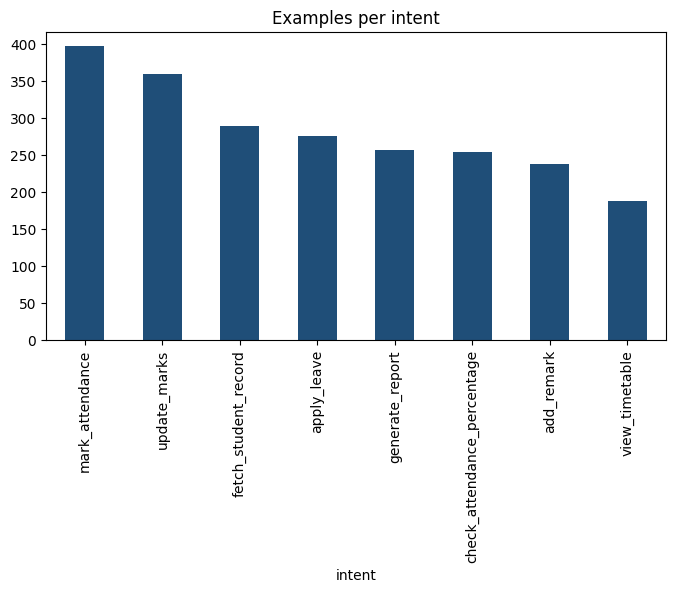

In [6]:
df['intent'].value_counts().plot(kind='bar', figsize=(8,4), color="#1F4E78", title="Examples per intent")


In [7]:
# Sanity check: print a few example sentences per intent
for intent in df["intent"].unique():
    print(f"\n--- {intent} ---")
    for text in df[df["intent"] == intent]["command_text"].sample(3, random_state=1):
        print(" ", text)



--- update_marks ---
  Please update Operating Systems grade for Yuvraj Singh to 60
  Please update Cloud Computing grade for Nandini Rao to 75
  Could you update marks of Priya Verma to 59 in Cybersecurity

--- check_attendance_percentage ---
  Kindly calculate Aarav Bhatia's attendance percentage
  How much attendance does Rohan Gupta have in Web Technologies
  Kindly check attendance percentage for Shreya Bansal in DBMS

--- apply_leave ---
  Submit a leave request for Dev Patel due to a conference
  Kindly put in a leave application for Fatima Khan for personal reasons
  Could you mark Kabir Mehra on leave this Tuesday for a family function

--- mark_attendance ---
  Could you mark Priya Verma absent in DBMS
  Kindly take attendance for Divya Menon today in Deep Learning
  Please mark Diya Saxena present in Web Technologies class

--- fetch_student_record ---
  Could you display information about Tanvi Bhatt
  Get the profile of Rohit Kumar
  Kindly fetch student details for Harsh

## 5. Save to CSV


In [8]:
df.to_csv("erp_voice_commands_dataset_v2.csv", index=False)
print("Saved erp_voice_commands_dataset_v2.csv with", len(df), "rows and", df["intent"].nunique(), "intents")
print("Rows per intent (min/max):", df['intent'].value_counts().min(), "/", df['intent'].value_counts().max())


Saved erp_voice_commands_dataset_v2.csv with 2257 rows and 8 intents
Rows per intent (min/max): 187 / 397


## What changed from v1 → v2

| | v1 | v2 |
|---|---|---|
| Students | 15 | 50 |
| Subjects | 10 | 20 |
| Marks values | 15 fixed values | 71 values (30–100, every integer) |
| Dates | 8 phrasings | 18 phrasings |
| Templates per intent | ~5 | ~8–10, incl. casual/question forms |
| Variants per template | 8 | 40 |
| **Result** | **507 rows** | **several thousand rows** (see printed count above) |

## Next steps

1. Re-run the intent classifier notebook on `erp_voice_commands_dataset_v2.csv` instead of the v1 file.
2. If the mentor still wants more scale, the easiest additional lever is adding a handful of genuinely
   hand-written sentences per intent (not from templates) and mixing them in — this adds real linguistic
   variety that template expansion alone can't fully replicate.
3. Keep v1 and v2 both around — v2 is for training/scale, but a small hand-written held-out test set
   (never seen by any template) is still the right way to report an honest accuracy number.
